## Setup

In [2]:
%pip -q install "transformers>=4.44,<5" "diffusers>=0.30,<0.38" accelerate safetensors pandas matplotlib

In [4]:
import json
import gc
from pathlib import Path
import pandas as pd
import torch
from google.colab import files

SEED = 42
STEPS = 2
GUIDANCE = 0.0
SIZE = 512
OUT_DIR = Path('/content/milestone1_outputs')
OUT_DIR.mkdir(exist_ok=True)

print('GPU:', torch.cuda.is_available())

GPU: True


## Load test prompts

In [5]:
# upload prompts_test.csv
uploaded = files.upload()
csv_name = next(name for name in uploaded if name.endswith('.csv'))
test_df = pd.read_csv(csv_name)

assert len(test_df) == 5
assert {'image_id', 'path_512', 'prompt'}.issubset(test_df.columns)

prompts = test_df['prompt'].tolist()
test_df.to_csv(OUT_DIR / 'prompts_test.csv', index=False)
test_df

Saving prompts_test.csv to prompts_test.csv


,image_id,file_name,path_512,prompt
0,397133,000000397133.jpg,images_512/000000397133.jpg,A person standing by a stove in a kitchen
1,219578,000000219578.jpg,images_512/000000219578.jpg,A dog and cat are sleeping together on an oran...
2,80671,000000080671.jpg,images_512/000000080671.jpg,A person is trying to ski down a snowy slope
3,173383,000000173383.jpg,images_512/000000173383.jpg,a two layered cake sits on a table top
4,179765,000000179765.jpg,images_512/000000179765.jpg,A black Honda motorcycle with a dark burgundy ...


## CLIP text embeddings

In [6]:
from transformers import CLIPModel, CLIPTokenizer

clip_name = 'openai/clip-vit-base-patch32'
tokenizer = CLIPTokenizer.from_pretrained(clip_name)
clip = CLIPModel.from_pretrained(clip_name).eval()

inputs = tokenizer(prompts, padding=True, truncation=True, return_tensors='pt')
with torch.no_grad():
    features = clip.get_text_features(**inputs)

embeddings = features.pooler_output if hasattr(features, 'pooler_output') else features
embeddings = embeddings.cpu()
print('Embeddings:', embeddings.shape)
print(embeddings[0, :8])

torch.save(embeddings, OUT_DIR / 'clip_embeddings.pt')
del clip, features
gc.collect()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Embeddings: torch.Size([5, 512])
tensor([-0.2920, -0.4489, -0.0145, -0.0857, -0.0728,  0.1715,  0.2455, -0.3227])


167

## Generate images

In [7]:
from diffusers import AutoPipelineForText2Image

assert torch.cuda.is_available(), 'Switch to a T4 GPU runtime in Colab'
model_name = 'stabilityai/sd-turbo'
pipe = AutoPipelineForText2Image.from_pretrained(
    model_name, torch_dtype=torch.float16, variant='fp16'
).to('cuda')

runs = []
for i, row in test_df.iterrows():
    generator = torch.Generator(device='cuda').manual_seed(SEED)
    image = pipe(
        row['prompt'], num_inference_steps=STEPS,
        guidance_scale=GUIDANCE, height=SIZE, width=SIZE,
        generator=generator
    ).images[0]

    name = f"generated_{i+1}_{row['image_id']}.png"
    image.save(OUT_DIR / name)
    runs.append({
        'image_id': int(row['image_id']), 'prompt': row['prompt'],
        'image': name, 'model': model_name, 'seed': SEED,
        'steps': STEPS, 'guidance_scale': GUIDANCE, 'size': SIZE
    })
    print('Saved:', name)

with open(OUT_DIR / 'test_runs.json', 'w') as f:
    json.dump(runs, f, indent=2)

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

scheduler_config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/574 [00:00<?, ?B/s]

... (16 outputs left out)

  0%|          | 0/2 [00:00<?, ?it/s]

Saved: generated_4_173383.png


  0%|          | 0/2 [00:00<?, ?it/s]

Saved: generated_5_179765.png


## Generated samples

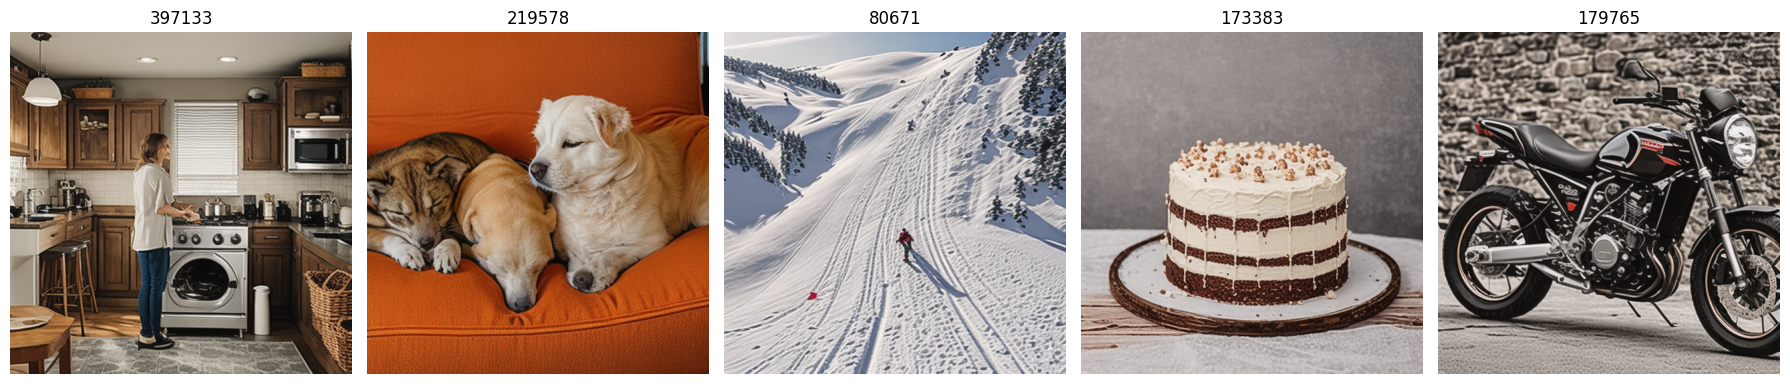

In [12]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, run in zip(axes, runs):
    ax.imshow(Image.open(OUT_DIR / run['image']))
    ax.set_title(str(run['image_id']))
    ax.axis('off')
plt.tight_layout()
plt.savefig(OUT_DIR / 'generated_gallery.png', dpi=150)
plt.show()

## Compare with COCO images

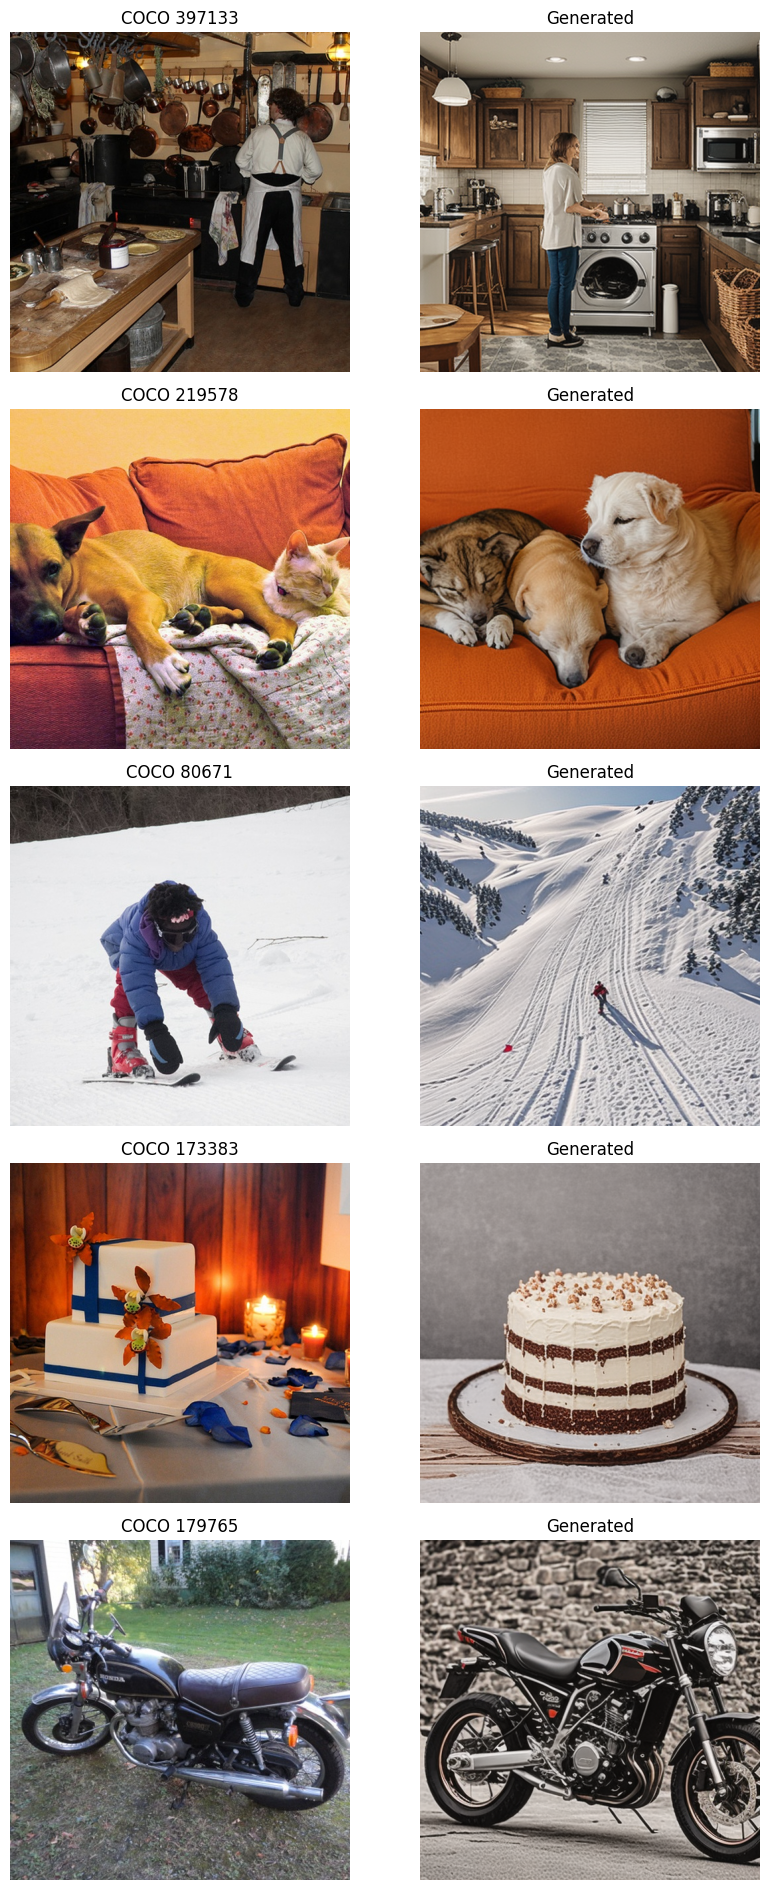

In [13]:
zip_path = '/content/coco_processed.zip'

from zipfile import ZipFile
from io import BytesIO

fig, axes = plt.subplots(5, 2, figsize=(9, 19))
with ZipFile(zip_path) as z:
    names = z.namelist()
    for i, row in test_df.reset_index(drop=True).iterrows():
        path = next(n for n in names if n.endswith(row['path_512']))
        real = Image.open(BytesIO(z.read(path))).convert('RGB')
        generated = Image.open(OUT_DIR / runs[i]['image'])

        axes[i, 0].imshow(real)
        axes[i, 1].imshow(generated)
        axes[i, 0].set_title(f"COCO {row['image_id']}")
        axes[i, 1].set_title('Generated')
        for ax in axes[i]:
            ax.axis('off')

plt.tight_layout()
plt.savefig(OUT_DIR / 'real_vs_generated.png', dpi=150)
plt.show()

## Save results

In [11]:
import shutil

zip_output = shutil.make_archive('/content/milestone1_outputs', 'zip', OUT_DIR)
print([p.name for p in OUT_DIR.iterdir()])
files.download(zip_output)

['generated_1_397133.png', 'generated_gallery.png', 'generated_4_173383.png', 'test_runs.json', 'real_vs_generated.png', 'generated_2_219578.png', 'generated_3_80671.png', 'prompts_test.csv', 'generated_5_179765.png', 'clip_embeddings.pt']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>